# INFO 4340 Final Project: LLM Spoiler Detection on IMDb Reviews

**Braxton Turner & Teenna Pachika**

**Question:** Can an LLM flag spoilers in movie reviews well enough to replace the reviewer's own
"contains spoilers" checkbox, and at what cost?

**Data:** IMDB Spoiler Dataset by Rishabh Misra (Kaggle). `sample_reviews.py` draws our samples from the raw files.

This notebook builds on the class notebooks in order, using the same code on our data:

| Part | Class | What it does here |
|---|---|---|
| 1 | Class 2: first API call | Ask about one review, repeat it, fact-check it |
| 2 | Classes 3-4: tokens and benchmarking | Token counts, context window math, cost estimate before we run |
| 3 | Classes 5-6, 8: data report and validation | Discover, data quality (code vs. AI), dictionary, cleaning steps, `run_validation()` |
| 4 | Classes 11-12 (+ 4): text classification | Hand labels and κ, sklearn baseline, LLM classifier, benchmark, formal evaluation, cost |
| 5 | Class 8: ask for it three times | Test our riskiest line, the answer parser |
| 6 | Class 7: impact analysis | How much the results change if we trust the dataset tag instead of our labels |
| 7 | Classes 13-14: evaluation | Rubric, human-human and human-LLM κ, judge sensitivity, MDD, eval harness |
| 8 | Our results | Confidence intervals, subgroups, decision |

**Dr. Stefani's corrections we applied (Week 7 feedback and class tips):**
- Our own hand labels are the answer key, not the dataset tag. Half the sample is borderline reviews (oversampled).
- Linear-weighted κ for every rubric comparison; MDD = mean + 1 SD of rater differences.
- Every comparison gets an MDD or a 95% bootstrap CI (1,000 resamples).
- Recall on spoilers is the headline metric (a missed spoiler costs more than a false flag).
- The model may answer **Unsure**, which sends the review to a human.
- Rubric calibrated together on our Week 7 answers before we scored 25 new ones on our own.
- Judge bias fixes: a different model judges, answer order shuffled every run, "length is not a criterion".
- Every AI answer is saved to `outputs/`, so reruns never call the API.

## Setup

In [1]:
import pandas as pd
import numpy as np
import json
import time
import re
import textwrap
import anthropic
import os
import tiktoken
from dotenv import load_dotenv
from collections import Counter
from itertools import combinations
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix,
                             cohen_kappa_score, precision_recall_fscore_support)
import matplotlib.pyplot as plt

# The only switch that spends money. Leave it False: answers are read from the saved files in outputs/.
RUN_API = False

try:
    from google.colab import userdata
    api_key = userdata.get("ANTHROPIC_API_KEY")
except ImportError:
    load_dotenv()                      # reads the key from a .env file that is never committed
    api_key = os.environ.get("ANTHROPIC_API_KEY")

if RUN_API:
    assert api_key is not None, "RUN_API is True but no API key was found"
    client = anthropic.Anthropic(api_key=api_key)

GEN_MODEL = "claude-sonnet-5-5"        # classifies the reviews (same model as Week 7)
JUDGE_MODEL = "claude-opus-5-5"        # a different model judges (self-preference fix, Class 14)
PRICE_INPUT = {"claude-sonnet-5-5": 2.00, "claude-opus-5-5": 4.00}     # $ per million input tokens
PRICE_OUTPUT = {"claude-sonnet-5-5": 10.00, "claude-opus-5-5": 20.00}  # $ per million output tokens

COST_MISSED_SPOILER = 5.0              # our assumption: a missed spoiler is 5x worse than
COST_FALSE_FLAG = 1.0                  # hiding a review that was fine
SEED = 42
N_BOOT = 1000
rng = np.random.default_rng(SEED)
os.makedirs("outputs", exist_ok=True)

val = pd.read_csv("data/validation_sample.csv")
train = pd.read_csv("data/train_sample.csv")
summary = json.load(open("data/corpus_summary.json"))
N_REVIEWS = len(val)                   # 100 hand-labeled reviews (4 groups of 25)
print(f"Loaded {len(val)} validation reviews and {len(train):,} training reviews")
print(f"RUN_API = {RUN_API}")

Loaded 100 validation reviews and 10,000 training reviews
RUN_API = False


In [2]:
def ask_claude(prompt, max_tokens=2000, model=GEN_MODEL):
    """Send a prompt to Claude and return the response text (Class 2)."""
    message = client.messages.create(
        model=model,
        max_tokens=max_tokens,
        messages=[{"role": "user", "content": prompt}],
    )
    # newer models think first, so keep only the text blocks
    return "".join(block.text for block in message.content if block.type == "text")


def print_response(response, width=80):
    """Print a response with word wrapping for readability."""
    print(textwrap.fill(response, width=width))
    print()


def load_or_call(path, make_calls, n_calls):
    """Class tip: save AI outputs to a file so reruns never call the API again."""
    if os.path.exists(path):
        print(f"Loaded saved answers from {path}, no API calls made\n")
        return json.load(open(path))
    assert RUN_API, f"No saved answers in {path}. Set RUN_API = True on purpose to make {n_calls} paid calls."
    result = make_calls()
    json.dump(result, open(path, "w"), indent=1)
    print(f"Made {n_calls} API calls and saved {path}\n")
    return result

## Part 1: First API call, repeat and compare (Class 2)

Same steps as Class 2 on one of our borderline reviews: ask once, ask again, and fact-check.
Class 2's temperature step is left out because current Claude models no longer accept a temperature setting.

In [3]:
print("#" * 60)
print("PART 1: First API call, repeat and compare")
print("#" * 60)
print()

review = val[val["borderline"]].iloc[0]
prompt_1 = ("Does this movie review contain spoilers? Answer Yes or No, then explain in one sentence.\n\n"
            f"Review:\n{review['review_text']}")

first_calls = load_or_call("outputs/class2_repeat.json",
                           lambda: [ask_claude(prompt_1) for _ in range(3)], 3)

print(f"REVIEW {review['review_id']}:")
print_response(review["review_text"][:400] + "...")
for i, response in enumerate(first_calls):
    print(f"--- Response {i+1} ---")
    print_response(response)

# Were the responses identical? LLMs are probabilistic, so "plausible" can vary from run to run
calls = [re.search(r"\b(Yes|No)\b", r).group(1) if re.search(r"\b(Yes|No)\b", r) else "?" for r in first_calls]
print(f"Calls across the 3 runs: {calls}")
print("Same call every time" if len(set(calls)) == 1 else "The call CHANGED between runs")
print()
print("### Fact-check ###")
print(f"  The reviewer's own tag says: {'spoiler' if review['is_spoiler'] else 'not a spoiler'}")
print("  The tag is self-reported, so the real check is against our hand labels (Part 4).")

############################################################
PART 1: First API call, repeat and compare
############################################################

Loaded saved answers from outputs/class2_repeat.json, no API calls made

REVIEW V001:
This little gem was worth an immediate Second Viewing, just to pick up on all of
the "little things" that I missed the first time.It's easy to just throw around
the name "Martin Scorsese", and assume that the movie is going to be good. But
the truth is that... sometimes... Scorsese is absolutely brilliant.I haven't
read the novel upon which this film is based, so all of my comments are based
upon ...

--- Response 1 ---
**Yes.** The review reveals major plot points of *Shutter Island*, including
that the protagonist may be deluding himself to escape his past, that he's
possibly being lobotomized, and how the film ends, even though it frames them as
open questions rather than stating them outright.

--- Response 2 ---
**Yes.** The review r

**What we noticed:**  We asked Claude about the same review three times, and it said Yes every time. The wording changed each run, though: each answer pointed to slightly different details of the ending, like the hero being a patient, his “partner,” or the lobotomy. So the call was stable but the explanation wasn’t. The reviewer’s own tag also says spoiler, but that tag is self-reported, so the real check is against our hand labels in Part 4.

## Part 2: Tokens, context windows and a cost estimate (Classes 3-4)

The three prompts are the Week 7 prompts (A basic, B + definition, C + definition + 2 examples), plus the
**Unsure** option from the feedback. Token counts here use the class tokenizer (GPT-4o's), so they are an
estimate; Claude's real counts come back with every answer and are compared in Part 4e.

In [4]:
FORMAT = ("Answer in exactly this format:\nSpoiler: Yes, No, or Unsure\nReason: one sentence explaining why\n"
          "Use Unsure only if you genuinely cannot tell; a human moderator will check those reviews.")

DEFINITION = ("A spoiler is any detail that reveals important plot events someone wouldn't know before watching, "
              "like the ending, a twist, a character dying, or who the villain is. "
              "General opinions about acting, visuals or whether the movie is good are NOT spoilers.\n\n")

EXAMPLES = ("Example 1: 'I can't believe the dad was the killer the whole time.'\n"
            "Spoiler: Yes\nReason: It reveals the identity of the killer, which is a major twist.\n\n"
            "Example 2: 'The acting was great but the movie dragged in the middle.'\n"
            "Spoiler: No\nReason: It only gives opinions about acting and pacing, not plot events.\n\n")

QUESTION = "Does this movie review contain spoilers?\n\n" + FORMAT + "\n\nReview:\n{review}"

PROMPTS = {
    "A": QUESTION,                           # basic, no definition
    "B": DEFINITION + QUESTION,              # adds a definition
    "C": DEFINITION + EXAMPLES + QUESTION,   # definition plus 2 examples
}

In [5]:
print("#" * 60)
print("PART 2: Tokens, context windows and cost")
print("#" * 60)
print()

enc = tiktoken.encoding_for_model("gpt-4o")


def show_tokens(text, label=""):
    """Display text as tokens with count."""
    tokens = enc.encode(text)
    decoded = [enc.decode([t]) for t in tokens]
    if label:
        print(f"## {label} ##")
    print(f"Text:     \"{text}\"")
    print(f"Tokens:   {decoded}")
    print(f"Count:    {len(tokens)} tokens")
    print()
    return len(tokens)


def compare_token_counts(*texts_and_labels):
    """Compare token counts across multiple texts."""
    results = []
    for text, label in texts_and_labels:
        count = len(enc.encode(text))
        results.append((label, count))
        print(f"  {label:30s}  {count:>6,} tokens")
    print()
    return results


show_tokens("The twist is that he was dead the whole time.", "A spoiler sentence")

by_length = val.sort_values("n_chars")
print("Token counts by review and prompt:")
compare_token_counts(
    (by_length["review_text"].iloc[0], "Shortest review"),
    (by_length["review_text"].iloc[len(val) // 2], "Median review"),
    (by_length["review_text"].iloc[-1], "Longest review"),
    (PROMPTS["A"].format(review=""), "Prompt A (no review)"),
    (PROMPTS["C"].format(review=""), "Prompt C (no review)"),
)

############################################################
PART 2: Tokens, context windows and cost
############################################################

## A spoiler sentence ##
Text:     "The twist is that he was dead the whole time."
Tokens:   ['The', ' twist', ' is', ' that', ' he', ' was', ' dead', ' the', ' whole', ' time', '.']
Count:    11 tokens

Token counts by review and prompt:
  Shortest review                     68 tokens
  Median review                      185 tokens
  Longest review                     317 tokens
  Prompt A (no review)                51 tokens
  Prompt C (no review)               175 tokens



[('Shortest review', 68),
 ('Median review', 185),
 ('Longest review', 317),
 ('Prompt A (no review)', 51),
 ('Prompt C (no review)', 175)]

In [6]:
# Context window math: how many reviews fit in one request?
tokens_per_review = int(np.mean([len(enc.encode(t)) for t in val["review_text"]]))
windows = {"Claude Sonnet": 200_000, "GPT-4o": 128_000, "Llama 3 (8B)": 8_000}

print(f"Average review: {tokens_per_review} tokens")
print("How many reviews fit in each context window? (leaving 20% for the prompt and response)")
for model, window in windows.items():
    usable = int(window * 0.8)
    print(f"  {model:15s}  {window:>8,} tokens  >  ~{usable // tokens_per_review:,} reviews")
print("We still send one review per call, so one bad answer can't spill into the others.")
print()

# Cost estimate BEFORE running (checked against the real token counts in Part 4f)
N_CALLS = len(val) * len(PROMPTS)
OUTPUT_TOKENS_EACH = 300                       # assumption: the model thinks before it answers
prompt_tokens = np.mean([len(enc.encode(PROMPTS[p].format(review=""))) for p in PROMPTS])
est_input = N_CALLS * (tokens_per_review + prompt_tokens)
est_output = N_CALLS * OUTPUT_TOKENS_EACH
est_cost = est_input / 1_000_000 * PRICE_INPUT[GEN_MODEL] + est_output / 1_000_000 * PRICE_OUTPUT[GEN_MODEL]

print(f"Scenario: classify {len(val)} reviews x {len(PROMPTS)} prompts = {N_CALLS} calls")
print(f"  Input tokens:  {est_input:,.0f}")
print(f"  Output tokens: {est_output:,.0f}  ({OUTPUT_TOKENS_EACH} per call, assumed)")
print(f"  Estimated cost: ${est_cost:.2f}")

Average review: 193 tokens
How many reviews fit in each context window? (leaving 20% for the prompt and response)
  Claude Sonnet     200,000 tokens  >  ~829 reviews
  GPT-4o            128,000 tokens  >  ~530 reviews
  Llama 3 (8B)        8,000 tokens  >  ~33 reviews
We still send one review per call, so one bad answer can't spill into the others.

Scenario: classify 100 reviews x 3 prompts = 300 calls
  Input tokens:  90,500
  Output tokens: 90,000  (300 per call, assumed)
  Estimated cost: $1.08


## Part 3: Data report and validation (Classes 5, 6, 8)

Cleaning was done in `sample_reviews.py` on the full 573,913 reviews and is checked again here:
1. Kept reviews of 300-1,500 characters. 2. Dropped blank and duplicate texts. 3. Dropped reviews with no genre.
4. Oversampled borderline reviews (twists, endings, deaths, hints, book changes): 50 borderline + 50 regular,
each split 25/25 by the dataset tag. 5. Drew a separate 10,000-review training sample (no overlap).

In [7]:
print("=" * 60)
print("PART 3a: DISCOVER")
print("=" * 60)
print()

print(f"Validation: {val.shape[0]} rows, {val.shape[1]} columns")
print(f"Training:   {train.shape[0]:,} rows, {train.shape[1]} columns\n")
val.info()
print()
print(val[["movie_rating", "rating", "n_chars"]].describe().round(2))
print()
print("### Missing values ###")
print(pd.DataFrame({"validation": val.isna().sum(), "training": train.isna().sum()}))
print()
print(f"Duplicate review texts: {pd.concat([val, train])['review_text'].duplicated().sum()}")
print(val["is_spoiler"].value_counts())

PART 3a: DISCOVER

Validation: 100 rows, 9 columns
Training:   10,000 rows, 8 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   review_id     100 non-null    object 
 1   movie_id      100 non-null    object 
 2   genre         100 non-null    object 
 3   movie_rating  100 non-null    float64
 4   rating        100 non-null    int64  
 5   is_spoiler    100 non-null    bool   
 6   borderline    100 non-null    bool   
 7   n_chars       100 non-null    int64  
 8   review_text   100 non-null    object 
dtypes: bool(2), float64(1), int64(2), object(4)
memory usage: 5.8+ KB

       movie_rating  rating  n_chars
count        100.00  100.00   100.00
mean           7.12    6.36   894.17
std            0.95    3.25   268.98
min            4.30    1.00   322.00
25%            6.40    3.00   694.25
50%            7.30    8.00   861.50
75%   

In [8]:
# Data quality issues found by code
both = pd.concat([val, train], ignore_index=True)
code_checks = {
    "glued words (lost punctuation)": both["review_text"].str.contains(r"\b[a-zA-Z]{20,}\b"),
    "no space after a period": both["review_text"].str.contains(r"[a-z]\.[A-Z][a-z]"),
    "non-ASCII characters": both["review_text"].str.contains(r"[^\x00-\x7F]"),
    "says 'spoiler' but tagged NOT spoiler": both["review_text"].str.contains(r"\bspoil", case=False) & ~both["is_spoiler"],
    "rating outside 1-10": ~both["rating"].between(1, 10),
}
code_found = pd.DataFrame({"issue": list(code_checks), "rows_affected": [int(m.sum()) for m in code_checks.values()]})
print("### Data quality issues found by code (validation + training) ###")
print(code_found.to_string(index=False))

### Data quality issues found by code (validation + training) ###
                                issue  rows_affected
       glued words (lost punctuation)             20
              no space after a period           4279
                 non-ASCII characters            582
says 'spoiler' but tagged NOT spoiler            249
                  rating outside 1-10              0


In [9]:
print("=" * 60)
print("PART 3b: AI DATA-QUALITY CHECK (Class 5)")
print("=" * 60)
print()

first_15 = val[["review_id", "movie_id", "genre", "movie_rating", "rating", "is_spoiler", "review_text"]].head(15)
AI_CHECK_PROMPT = ("Here are the first 15 rows of a movie-review dataset as CSV. Identify all data quality issues. "
                   "For each issue give: the column, how many of these 15 rows are affected, and one example.\n\n"
                   + first_15.to_csv(index=False))

ai_check = load_or_call("outputs/ai_check_data_quality.json",
                        lambda: {"prompt": AI_CHECK_PROMPT, "answer": ask_claude(AI_CHECK_PROMPT, 4000)}, 1)
print("### AI found ###")
print(ai_check["answer"])
print()
print("### Code found ###")
print(code_found.to_string(index=False))

PART 3b: AI DATA-QUALITY CHECK (Class 5)

Loaded saved answers from outputs/ai_check_data_quality.json, no API calls made

### AI found ###
# Data quality issues in the first 15 rows

| # | Column | Rows affected | Issue | Example |
|---|--------|---------------|-------|---------|
| 1 | `review_text` | 10 (V001, V002, V005, V007, V009, V010, V011, V012, V013, V014) | Missing space after sentence-ending punctuation. This looks like `<br>` tags stripped without a replacement space, and it merges words and sentences. | V001: "…the first time.It's easy to just throw around…" |
| 2 | `is_spoiler` | about 6 (V002, V004, V005, V006, V008, V012) | Labels look unreliable. V002 is `False` although it opens with "Spoiler ahead:" and discusses the plot. V004, V005, V006, V008 and V012 are `True` but contain no real plot reveals. | V006 (Rocky): `True`, but it only praises the film and says "you know what happens". |
| 3 | `is_spoiler` | 15 (class balance) | 8 of 15 rows are `True` (53%), which is 

**AI found / code found / AI missed:** Both caught the missing space after periods. The AI saw it in 10 of its 15 rows, and code found it in 4,279 reviews. Both also caught bad spoiler tags: the AI pointed to V002, which says "Spoiler ahead" but is tagged not spoiler, and code found 249 reviews like that. Only the AI found the softer problems, like ratings that contradict the text, scores written inside the review (like "6/10"), typos, and confusing column names. The AI missed the non-ASCII characters that code found in 582 reviews. It also only looked at 15 rows, so it can't tell how big a problem is. Code can.

In [10]:
print("=" * 60)
print("PART 3c: DATA DICTIONARY")
print("=" * 60)
print()

descriptions = {
    "review_id": ("our ID for the 100 validation reviews (V001-V100)", "created in sample_reviews.py"),
    "movie_id": ("IMDb movie ID", "kept; links each review to its genres"),
    "genre": ("the movie's genres, comma-separated", "split for subgroup analysis"),
    "movie_rating": ("the movie's IMDb rating (0-10)", "descriptive only"),
    "rating": ("the reviewer's star rating (1-10)", "descriptive only"),
    "is_spoiler": ("reviewer ticked 'contains spoilers'", "NOT the answer key; our hand labels are"),
    "borderline": ("mentions twists/ending/death/book etc.", "used to oversample hard reviews"),
    "n_chars": ("review length in characters", "used to check the CSV round trip"),
    "review_text": ("the review", "whitespace stripped; blanks and duplicates dropped"),
}
data_dictionary = pd.DataFrame([
    {"column": col, "type": str(val[col].dtype), "description": d, "n_missing": int(val[col].isna().sum()),
     "cleaning_decision": c} for col, (d, c) in descriptions.items()])
print(data_dictionary.to_string(index=False))
assert set(descriptions) == set(val.columns), "dictionary and data columns don't match"

PART 3c: DATA DICTIONARY

      column    type                                       description  n_missing                                  cleaning_decision
   review_id  object our ID for the 100 validation reviews (V001-V100)          0                       created in sample_reviews.py
    movie_id  object                                     IMDb movie ID          0              kept; links each review to its genres
       genre  object               the movie's genres, comma-separated          0                        split for subgroup analysis
movie_rating float64                    the movie's IMDb rating (0-10)          0                                   descriptive only
      rating   int64                 the reviewer's star rating (1-10)          0                                   descriptive only
  is_spoiler    bool               reviewer ticked 'contains spoilers'          0            NOT the answer key; our hand labels are
  borderline    bool            mentions tw

In [11]:
print("=" * 60)
print("PART 3d: CLEANING STEPS AND DATA LOSS (Class 6)")
print("=" * 60)
print()

steps = pd.read_csv("data/cleaning_steps.csv")
print(steps.to_string(index=False))
print()

rows = steps.set_index("step")["rows"]
assert rows["0 raw file"] == 573_913
assert rows["1 kept 300-1,500 characters"] + rows["   (dropped: outside 300-1,500 chars)"] == rows["0 raw file"], \
    "length filter lost rows it didn't report"
assert rows["4 dropped reviews with no genre"] == summary["after_cleaning_with_genre"]
print(f"Kept overall: {rows['4 dropped reviews with no genre']:,} of {rows['0 raw file']:,} "
      f"({rows['4 dropped reviews with no genre'] / rows['0 raw file']:.1%})")

share = steps.set_index("step")["spoiler_share"]
print(f"Reviews dropped by the length filter are {share['   (dropped: outside 300-1,500 chars)']:.1%} spoilers "
      f"vs. {share['1 kept 300-1,500 characters']:.1%} of the reviews kept.")
print("So our results apply to 300-1,500 character reviews only; long reviews spoil more often.")

# CSV round trip: saved text must be exactly as long as when it was sampled
for name, df in [("validation", val), ("training", train)]:
    n_changed = (df["review_text"].str.len() != df["n_chars"]).sum()
    assert n_changed == 0, f"{name}: review text was cut or changed when saved/loaded"
print("CSV round trip: 0 reviews changed")

PART 3d: CLEANING STEPS AND DATA LOSS (Class 6)

                                 step   rows  spoiler_share  mean_rating  median_chars  n_movies
                           0 raw file 573913         0.2630        6.954          1052      1572
   (dropped: outside 300-1,500 chars) 202080         0.3640        7.049          2264      1571
          1 kept 300-1,500 characters 371833         0.2081        6.903           824      1572
              2 dropped blank reviews 371833         0.2081        6.903           824      1572
            3 dropped duplicate texts 371473         0.2082        6.902           824      1572
      4 dropped reviews with no genre 371468         0.2082        6.902           824      1570
    5a validation sample (stratified)    100         0.5000        6.360           861        94
          5b training sample (random)  10000         0.2070        6.909           822      1467

Kept overall: 371,468 of 573,913 (64.7%)
Reviews dropped by the length filter

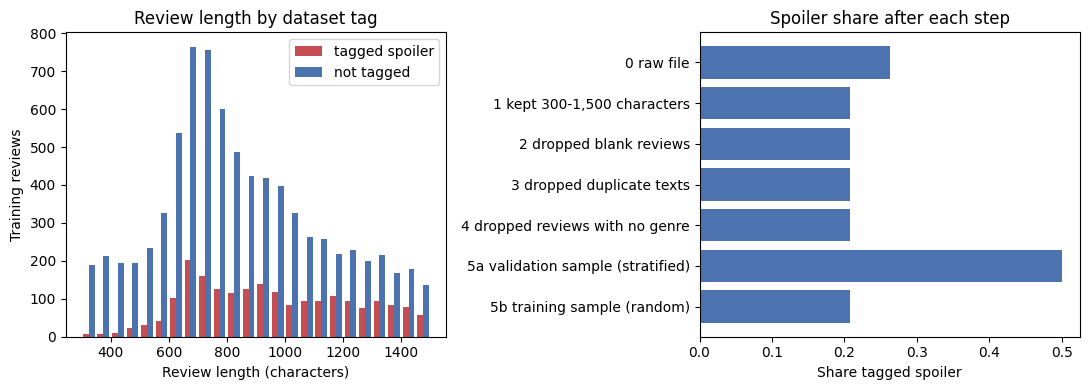

In [12]:
# Two visualizations (Class 6 checklist)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist([train.loc[train["is_spoiler"], "n_chars"], train.loc[~train["is_spoiler"], "n_chars"]],
             bins=24, label=["tagged spoiler", "not tagged"], color=["#C44E52", "#4C72B0"])
axes[0].set_xlabel("Review length (characters)")
axes[0].set_ylabel("Training reviews")
axes[0].set_title("Review length by dataset tag")
axes[0].legend()

main_steps = steps[~steps["step"].str.startswith(" ")]
axes[1].barh(main_steps["step"], main_steps["spoiler_share"], color="#4C72B0")
axes[1].set_xlabel("Share tagged spoiler")
axes[1].set_title("Spoiler share after each step")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("outputs/fig_data.png", dpi=150)
plt.show()

In [13]:
def run_validation(val, train, config=None):
    """
    Run a battery of validation checks on the samples (Class 8).

    Returns
    -------
    DataFrame
        A pass/fail report for each check.
    """
    if config is None:
        config = {"expected_val_rows": 100, "expected_train_rows": 10_000, "rows_per_stratum": 25,
                  "min_chars": 300, "max_chars": 1500}

    checks = []
    checks.append({"check": "Validation row count", "passed": len(val) == config["expected_val_rows"],
                   "detail": f"{len(val)} rows loaded"})
    checks.append({"check": "Training row count", "passed": len(train) == config["expected_train_rows"],
                   "detail": f"{len(train):,} rows loaded"})

    n_dupes = val["review_id"].duplicated().sum()
    checks.append({"check": "Unique review IDs", "passed": n_dupes == 0, "detail": f"{n_dupes} duplicate IDs"})

    strata = val.groupby(["borderline", "is_spoiler"]).size()
    checks.append({"check": "Stratified sample (4 x 25)",
                   "passed": len(strata) == 4 and (strata == config["rows_per_stratum"]).all(),
                   "detail": f"strata sizes {strata.tolist()}"})

    overlap = len(set(train["review_text"]) & set(val["review_text"]))
    checks.append({"check": "No train/validation overlap", "passed": overlap == 0, "detail": f"{overlap} shared"})

    n_chars = val["review_text"].str.len()
    checks.append({"check": "Review length window",
                   "passed": n_chars.between(config["min_chars"], config["max_chars"]).all(),
                   "detail": f"shortest {n_chars.min()}, longest {n_chars.max()}"})

    n_missing = val[["review_text", "genre"]].isna().sum().sum()
    checks.append({"check": "No missing text or genre", "passed": n_missing == 0, "detail": f"{n_missing} missing"})
    return pd.DataFrame(checks)


report = run_validation(val, train)
print("### Validation Report ###\n")
for _, row in report.iterrows():
    print(f"  {'PASS' if row['passed'] else 'FAIL'}  {row['check']:<30s}  {row['detail']}")
print(f"\n  Result: {report['passed'].sum()}/{len(report)} checks passed")
assert report["passed"].all(), "fix the failing checks before going on"

# one row per review x genre, for the subgroup analysis in Part 8
genres = val.assign(genre_one=val["genre"].str.split(", ")).explode("genre_one")
assert genres["review_id"].nunique() == N_REVIEWS, "a review was lost when splitting genres"

### Validation Report ###

  PASS  Validation row count            100 rows loaded
  PASS  Training row count              10,000 rows loaded
  PASS  Unique review IDs               0 duplicate IDs
  PASS  Stratified sample (4 x 25)      strata sizes [25, 25, 25, 25]
  PASS  No train/validation overlap     0 shared
  PASS  Review length window            shortest 322, longest 1455
  PASS  No missing text or genre        0 missing

  Result: 7/7 checks passed


## Part 4: Text classification (Classes 11-12)

### 4a. Hand-coded answer key and inter-annotator reliability
Both of us labeled all 100 reviews on our own (`labeling/hand_labels_*.csv`) using the rules in
`labeling/LABELING_GUIDE.md`. κ is computed **before** we talk. Then we settle each disagreement together in
`labeling/answer_key.csv`.

In [14]:
print("#" * 60)
print("PART 4a: HAND-CODING AND INTER-ANNOTATOR RELIABILITY")
print("#" * 60)
print()

RATERS = ["braxton", "teenna"]
hand = {}
for rater in RATERS:
    sheet = pd.read_csv(f"labeling/hand_labels_{rater}.csv", dtype={"label": str})
    sheet["label"] = sheet["label"].str.strip().str.capitalize()
    n_blank = (~sheet["label"].isin(["Yes", "No"])).sum()
    assert len(sheet) == N_REVIEWS and n_blank == 0, f"{rater}: {n_blank} labels are not Yes/No. Finish labeling first."
    hand[rater] = sheet.set_index("review_id")["label"]

labels = pd.DataFrame(hand).loc[val["review_id"]]
your_labels = labels["braxton"].tolist()
partner_labels = labels["teenna"].tolist()

kappa = cohen_kappa_score(your_labels, partner_labels)
print(f"Cohen's κ = {kappa:.3f}")
print(f"Disagreements: {(labels['braxton'] != labels['teenna']).sum()} of {len(labels)}")

if kappa < 0.6:
    print("κ < 0.6 - revise your coding scheme and re-code")
    print("  Common fixes: clarify category boundaries, add examples,")
    print("  resolve ambiguous cases with explicit rules")
elif kappa < 0.8:
    print("Moderate to substantial agreement - acceptable")
else:
    print("Strong agreement - coding scheme is reliable")
print()

############################################################
PART 4a: HAND-CODING AND INTER-ANNOTATOR RELIABILITY
############################################################

Cohen's κ = 0.299
Disagreements: 38 of 100
κ < 0.6 - revise your coding scheme and re-code
  Common fixes: clarify category boundaries, add examples,
  resolve ambiguous cases with explicit rules



In [15]:
# Final answer key: agreed labels carry over; disagreements are settled by talking them through
key_path = "labeling/answer_key.csv"
if not os.path.exists(key_path):
    key = labels.copy()
    key["final_label"] = np.where(labels["braxton"] == labels["teenna"], labels["braxton"], "")
    key["how_settled"] = ""
    key.to_csv(key_path)
    print(f"Wrote {key_path}: fill final_label and how_settled for each disagreement, then rerun.")
key = pd.read_csv(key_path, dtype=str).set_index("review_id").loc[val["review_id"]]
n_unsettled = (~key["final_label"].isin(["Yes", "No"])).sum()
assert n_unsettled == 0, f"{n_unsettled} disagreements still unsettled in {key_path}"

true_labels = key["final_label"].to_numpy()
val["truth"] = true_labels == "Yes"
print(f"Answer key: {val['truth'].sum()} spoilers out of {len(val)} reviews")

# How good is the reviewer's own tag, measured against our key?
tag_labels = np.where(val["is_spoiler"], "Yes", "No")
tag_agree = (tag_labels == true_labels).mean()
print(f"Dataset tag matches our key on {tag_agree:.1%} of reviews (κ = {cohen_kappa_score(tag_labels, true_labels):.3f})")
print(pd.crosstab(tag_labels, true_labels, rownames=["dataset tag"], colnames=["our key"]))

Answer key: 45 spoilers out of 100 reviews
Dataset tag matches our key on 57.0% of reviews (κ = 0.140)
our key      No  Yes
dataset tag         
No           31   19
Yes          24   26


### 4b. Non-AI baselines and sklearn classifier
A majority-class guess, a keyword rule, and the Class 11 TF-IDF + logistic regression. We don't have hand labels
for 10,000 reviews, so the sklearn model trains on the dataset tag, then is tested on our 100 hand-labeled reviews.

In [16]:
print("#" * 60)
print("PART 4b: BASELINES AND SKLEARN CLASSIFIER")
print("#" * 60)
print()

KEYWORDS = r"\b(?:twists?|ending|the end|dies|died|death|killed|kills|reveals?|turns out|spoilers?)\b"
preds = pd.DataFrame(index=val["review_id"])
preds["majority (always No)"] = "No"
preds["keyword rule"] = np.where(val["review_text"].str.contains(KEYWORDS, case=False), "Yes", "No")

vectorizer = TfidfVectorizer(max_features=500, stop_words="english")
X = vectorizer.fit_transform(train["review_text"].tolist())
train_labels = np.where(train["is_spoiler"], "Yes", "No")

# Class 11 settings plus class_weight="balanced": only 20% of training reviews are spoilers, and with the
# class defaults the model predicts "No" for every review (recall 0), which makes it a useless baseline
default_yes = (LogisticRegression(max_iter=1000, random_state=42, C=1.0).fit(X, train_labels).predict(X) == "Yes").sum()
print(f"With the class defaults the model predicts Yes for {default_yes} of {len(train):,} training reviews")
clf = LogisticRegression(max_iter=1000, random_state=42, C=1.0, class_weight="balanced")
cv_scores = cross_val_score(clf, X, train_labels, cv=5, scoring="f1_macro")
print(f"5-fold CV F1 (macro), against the dataset tag: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

clf.fit(X, train_labels)
preds["TF-IDF + logistic"] = clf.predict(vectorizer.transform(val["review_text"].tolist()))
print(preds.apply(pd.Series.value_counts).fillna(0).astype(int))

############################################################
PART 4b: BASELINES AND SKLEARN CLASSIFIER
############################################################

With the class defaults the model predicts Yes for 245 of 10,000 training reviews
5-fold CV F1 (macro), against the dataset tag: 0.564 ± 0.007
     majority (always No)  keyword rule  TF-IDF + logistic
No                    100            65                 46
Yes                     0            35                 54


### 4c. LLM classifier
100 reviews x 3 prompts = 300 answers, saved to `outputs/llm_outputs.json` (275 new calls; the 25 prompt C answers we scored with the rubric are reused).

In [17]:
print("#" * 60)
print("PART 4c: LLM CLASSIFIER")
print("#" * 60)
print()


def parse_call(answer):
    """Pull Yes / No / Unsure out of 'Spoiler: ...'; anything else is a parse error."""
    match = re.search(r"Spoiler:\s*\**\s*(Yes|No|Unsure)", str(answer), re.IGNORECASE)
    if match:
        return match.group(1).capitalize()
    return "parse_error"


assert parse_call("Spoiler: Yes\nReason: x") == "Yes"
assert parse_call("**Spoiler:** unsure") == "Unsure"
assert parse_call("I think so") == "parse_error"


def classify_text(text, prompt_name):
    """Classify a single review, tracking tokens and time."""
    start = time.time()
    response = client.messages.create(
        model=GEN_MODEL,
        max_tokens=2000,
        messages=[{"role": "user", "content": PROMPTS[prompt_name].format(review=text)}]
    )
    elapsed = time.time() - start
    return {
        "answer": "".join(block.text for block in response.content if block.type == "text"),
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "response_time_s": round(elapsed, 2),
    }


# The 25 prompt C answers we scored with the rubric were pulled first (pull_rubric_answers.py); reuse them
rubric_answers = {(r["prompt"], r["review_id"]): r for r in json.load(open("outputs/rubric_answers_25.json"))}


def run_all_prompts():
    results = []
    for prompt_name in PROMPTS:
        for _, row in val.iterrows():
            if (prompt_name, row["review_id"]) in rubric_answers:
                results.append(dict(rubric_answers[(prompt_name, row["review_id"])]))
                continue
            result = classify_text(row["review_text"], prompt_name)
            result["prompt"] = prompt_name
            result["review_id"] = row["review_id"]
            results.append(result)
        print(f"  Prompt {prompt_name}: done")
    return results


n_calls = N_REVIEWS * len(PROMPTS)
llm_df = pd.DataFrame(load_or_call("outputs/llm_outputs.json", run_all_prompts, n_calls - len(rubric_answers)))
assert len(llm_df) == n_calls and (llm_df.groupby("prompt").size() == N_REVIEWS).all(), "expected 3 prompts x 100 reviews"

llm_df["call"] = llm_df["answer"].apply(parse_call)
print(f"Parse errors: {(llm_df['call'] == 'parse_error').sum()}")
print(pd.crosstab(llm_df["prompt"], llm_df["call"]))

for prompt_name in PROMPTS:
    one_prompt = llm_df[llm_df["prompt"] == prompt_name].set_index("review_id")
    preds[f"LLM prompt {prompt_name}"] = one_prompt.loc[preds.index, "call"]
assert preds.notna().all().all(), "a review lost its prediction when the answers were matched back"

############################################################
PART 4c: LLM CLASSIFIER
############################################################

Loaded saved answers from outputs/llm_outputs.json, no API calls made

Parse errors: 0
call    No  Yes
prompt         
A       77   23
B       78   22
C       76   24


In [18]:
# Class 4 benchmark: the same 100 reviews under 3 prompt configurations
print("### Performance by Prompt (Class 4) ###")
perf_summary = llm_df.groupby("prompt").agg(
    mean_time=("response_time_s", "mean"),
    std_time=("response_time_s", "std"),
    mean_input_tokens=("input_tokens", "mean"),
    mean_output_tokens=("output_tokens", "mean"),
).round(2)
print(perf_summary.to_string())

### Performance by Prompt (Class 4) ###
        mean_time  std_time  mean_input_tokens  mean_output_tokens
prompt                                                            
A            1.53      0.46             388.67               72.79
B            1.74      0.67             467.67               97.09
C            1.65      0.45             586.67               89.81


### 4d. Formal evaluation against our answer key
Positive class = spoiler. **Unsure counts as a flag** (the review stays hidden until a human checks it), and a
parse error counts as "No" (the worst case).

In [19]:
print("#" * 60)
print("PART 4d: FORMAL EVALUATION")
print("#" * 60)
print()


def to_flag(pred_labels):
    """Unsure -> Yes (hidden until a human checks); anything else that isn't Yes -> No."""
    return np.array(["Yes" if p in ["Yes", "Unsure"] else "No" for p in pred_labels])


def evaluate(true_labels, pred_labels):
    """Spoiler-class precision/recall/F1, share sent to a human, and our cost-weighted error."""
    flags = to_flag(pred_labels)
    p, r, f1, _ = precision_recall_fscore_support(true_labels, flags, labels=["Yes"], zero_division=0)
    missed = ((true_labels == "Yes") & (flags == "No")).sum()
    false_flags = ((true_labels == "No") & (flags == "Yes")).sum()
    return {"recall": r[0], "precision": p[0], "f1": f1[0], "accuracy": (flags == true_labels).mean(),
            "to_human": (np.array(pred_labels) == "Unsure").mean(),
            "missed_spoilers": int(missed), "false_flags": int(false_flags),
            "error_cost_per_100": 100 * (missed * COST_MISSED_SPOILER + false_flags * COST_FALSE_FLAG) / len(true_labels)}


results = pd.DataFrame({m: evaluate(true_labels, preds[m].values) for m in preds.columns}).T
print(results.round(3).to_string())
print()

llm_cols = [c for c in preds.columns if c.startswith("LLM")]
best = results.loc[llm_cols, "f1"].astype(float).idxmax()
print(f"Best prompt by F1: {best}\n")

print(f"### Classification Report ({best} vs. hand-coded) ###")
print(classification_report(true_labels, to_flag(preds[best].values), zero_division=0))

print("### Confusion Matrix ###")
cm = confusion_matrix(true_labels, to_flag(preds[best].values), labels=["Yes", "No"])
print(pd.DataFrame(cm, index=["true:Yes", "true:No"], columns=["pred:Yes", "pred:No"]))

# Cross-check (Class 6): recall two ways must match
recall_by_hand = cm[0, 0] / (cm[0, 0] + cm[0, 1])
assert abs(recall_by_hand - results.loc[best, "recall"]) < 1e-9, "the two recall calculations disagree"
assert cm.sum() == len(val), "the confusion matrix lost reviews"
print(f"\nCross-check: recall from the matrix {recall_by_hand:.3f} = sklearn {results.loc[best, 'recall']:.3f}")

############################################################
PART 4d: FORMAL EVALUATION
############################################################

                      recall  precision     f1  accuracy  to_human  missed_spoilers  false_flags  error_cost_per_100
majority (always No)   0.000      0.000  0.000      0.55       0.0             45.0          0.0               225.0
keyword rule           0.511      0.657  0.575      0.66       0.0             22.0         12.0               122.0
TF-IDF + logistic      0.711      0.593  0.646      0.65       0.0             13.0         22.0                87.0
LLM prompt A           0.444      0.870  0.588      0.72       0.0             25.0          3.0               128.0
LLM prompt B           0.422      0.864  0.567      0.71       0.0             26.0          3.0               133.0
LLM prompt C           0.467      0.875  0.609      0.73       0.0             24.0          3.0               123.0

Best prompt by F1: LLM prompt 

In [20]:
print("#" * 60)
print("PART 4e: COST ANALYSIS")
print("#" * 60)
print()

INPUT_RATE = PRICE_INPUT[GEN_MODEL] / 1_000_000
OUTPUT_RATE = PRICE_OUTPUT[GEN_MODEL] / 1_000_000
llm_df["cost_usd"] = llm_df["input_tokens"] * INPUT_RATE + llm_df["output_tokens"] * OUTPUT_RATE

total_cost = llm_df["cost_usd"].sum()
print(f"All {len(llm_df)} calls:")
print(f"  Total input tokens:  {llm_df['input_tokens'].sum():,}")
print(f"  Total output tokens: {llm_df['output_tokens'].sum():,}")
print(f"  Total cost:          ${total_cost:.4f}   (Part 2 estimated ${est_cost:.2f})")

# Cross-check (Class 6): total cost two ways must match
assert abs(total_cost - (llm_df["input_tokens"].sum() * INPUT_RATE + llm_df["output_tokens"].sum() * OUTPUT_RATE)) < 1e-9

best_letter = best[-1]
cost_per_text = llm_df.loc[llm_df["prompt"] == best_letter, "cost_usd"].mean()
mean_time = llm_df.loc[llm_df["prompt"] == best_letter, "response_time_s"].mean()
print(f"\n### Cost Projections ({best}) ###")
for n in [100, 1_000, 10_000, 100_000]:
    print(f"  {n:>7,} texts:  ${cost_per_text * n:>8.2f}  ({mean_time * n / 60:>6.0f} min)")

HUMAN_RATE = 25.00     # $ per hour (class assumption)
TEXTS_PER_HOUR = 40    # human coding rate (class assumption)
print("\n### Human vs. LLM Cost Comparison ###")
for n in [100, 1_000, 10_000]:
    human_cost = (n / TEXTS_PER_HOUR) * HUMAN_RATE
    llm_cost = cost_per_text * n
    print(f"  {n:>7,} texts:  Human=${human_cost:>8.2f}  LLM=${llm_cost:>8.2f}  (LLM is {human_cost / llm_cost:.0f}x cheaper)")
to_human = results.loc[best, "to_human"]
print(f"\nBut {to_human:.0%} of reviews are Unsure and still go to a person: "
      f"about {to_human * 10_000 / TEXTS_PER_HOUR * HUMAN_RATE:,.0f} dollars of review time per 10,000 reviews.")

############################################################
PART 4e: COST ANALYSIS
############################################################

All 300 calls:
  Total input tokens:  144,301
  Total output tokens: 25,969
  Total cost:          $0.5483   (Part 2 estimated $1.08)

### Cost Projections (LLM prompt C) ###
      100 texts:  $    0.21  (     3 min)
    1,000 texts:  $    2.07  (    28 min)
   10,000 texts:  $   20.71  (   276 min)
  100,000 texts:  $  207.14  (  2757 min)

### Human vs. LLM Cost Comparison ###
      100 texts:  Human=$   62.50  LLM=$    0.21  (LLM is 302x cheaper)
    1,000 texts:  Human=$  625.00  LLM=$    2.07  (LLM is 302x cheaper)
   10,000 texts:  Human=$ 6250.00  LLM=$   20.71  (LLM is 302x cheaper)

But 0% of reviews are Unsure and still go to a person: about 0 dollars of review time per 10,000 reviews.


## Part 5: Ask for it three times (Class 8)

Our riskiest line is `parse_call()`: if it misreads an answer, a review silently loses its prediction.
We ask the model three times, in fresh conversations, to write that pattern, then test every version against the
300 real answers.

In [21]:
print("=" * 60)
print("PART 5: ASK FOR IT THREE TIMES")
print("=" * 60)
print()

PARSE_QUESTION = """I have model answers like these (one per review):

Spoiler: Yes
Reason: It reveals the killer.

**Spoiler:** No
**Reason:** Only opinions about acting.

Spoiler: Unsure
Reason: It hints at a twist but doesn't say what it is.

Write ONE Python regular expression that captures Yes, No, or Unsure as group 1. \
Return ONLY the regex pattern, no explanation, no code fences."""

N_ATTEMPTS = 3
attempts = load_or_call("outputs/ask_three_times.json",
                        lambda: [ask_claude(PARSE_QUESTION).strip() for _ in range(N_ATTEMPTS)], N_ATTEMPTS)


def normalize(code_str):
    """Strip markdown fences and whitespace so we compare the code itself."""
    code_str = re.sub(r"```[a-z]*", "", code_str)
    return " ".join(code_str.split()).strip("` ")


normed = [normalize(a) for a in attempts]
counts = Counter(normed)
for text, n in counts.most_common():
    print(f"[{n}/{N_ATTEMPTS}]  {text}")
print()
if len(counts) == 1:
    print(f"All {N_ATTEMPTS} identical = a well-trodden pattern.")
    print("Usually safe. Not always. See the data test below.")
else:
    print(f"{len(counts)} DIFFERENT ANSWERS to one question.")
    print("The model was guessing. That line needs your attention.")
print()

# The real test: how many of the 300 answers does each pattern parse?
approaches = {"ours: parse_call()": r"Spoiler:\s*\**\s*(Yes|No|Unsure)"}
for i, pattern in enumerate(normed, 1):
    approaches[f"attempt {i}"] = pattern.strip("r").strip("'\"")

print(f"{'approach':<22} {'parsed':>8} {'LOST':>8}")
for name, pattern in approaches.items():
    try:
        compiled = re.compile(pattern, re.IGNORECASE)
        n_ok = sum(1 for a in llm_df["answer"].astype(str)
                   if (m := compiled.search(a)) and m.groups() and str(m.group(1)).capitalize() in ["Yes", "No", "Unsure"])
        flag = "  <-- silent data loss" if n_ok < len(llm_df) else ""
        print(f"{name:<22} {n_ok:>8} {len(llm_df) - n_ok:>8}{flag}")
    except re.error as e:
        print(f"{name:<22} {'ERROR':>8}   {type(e).__name__}")
print("\nConsistency is not correctness: only the row counts verify a pattern.")

PART 5: ASK FOR IT THREE TIMES

Loaded saved answers from outputs/ask_three_times.json, no API calls made

[2/3]  (?i)\*{0,2}Spoiler\*{0,2}\s*:\s*\*{0,2}\s*(Yes|No|Unsure)\b
[1/3]  (?i)\*{0,2}Spoiler\*{0,2}:?\*{0,2}\s*(Yes|No|Unsure)\b

2 DIFFERENT ANSWERS to one question.
The model was guessing. That line needs your attention.

approach                 parsed     LOST
ours: parse_call()          300        0
attempt 1                   300        0
attempt 2                   300        0
attempt 3                   300        0

Consistency is not correctness: only the row counts verify a pattern.


## Part 6: Impact analysis (Class 7)

Class 7 compared a bugged pipeline to a fixed one. Our "bug" would be trusting the reviewer's own tag as the
truth. Same predictions, two answer keys: how much would our conclusions change?

In [22]:
print("=" * 70)
print("PART 6: QUANTITATIVE IMPACT ANALYSIS")
print("=" * 70)
print()


def run_pipeline(truth):
    """Score every method against one answer key."""
    scored = pd.DataFrame({m: evaluate(truth, preds[m].values) for m in preds.columns}).T
    top = scored.loc[llm_cols, "f1"].astype(float).idxmax()
    return {"best_prompt": top, "recall": scored.loc[top, "recall"], "precision": scored.loc[top, "precision"],
            "tfidf_recall": scored.loc["TF-IDF + logistic", "recall"], "spoilers": int((truth == "Yes").sum())}


bugged = run_pipeline(tag_labels)       # dataset tag as truth
fixed = run_pipeline(true_labels)       # our hand-labeled key as truth

print("### Pipeline Comparison ###\n")
print(f"{'Metric':<30s} {'Tag as truth':>15s} {'Our key':>15s} {'Difference':>15s}")
print("─" * 75)
print(f"{'Spoilers in the 100 reviews':<30s} {bugged['spoilers']:>15d} {fixed['spoilers']:>15d} {bugged['spoilers'] - fixed['spoilers']:>+15d}")
for metric in ["recall", "precision", "tfidf_recall"]:
    print(f"{metric:<30s} {bugged[metric]:>15.3f} {fixed[metric]:>15.3f} {bugged[metric] - fixed[metric]:>+15.3f}")
match = "Match" if bugged["best_prompt"] == fixed["best_prompt"] else "DIFFERS"
print(f"{'Best prompt':<30s} {bugged['best_prompt'][-1]:>15s} {fixed['best_prompt'][-1]:>15s} {match:>15s}")

print("\n### Stakeholder Impact Summary ###\n")
diff = bugged["recall"] - fixed["recall"]
print("If we had trusted the dataset tag:")
print(f"  --> Recall would be {'overstated' if diff > 0 else 'understated'} by {abs(diff):.3f}")
if match == "DIFFERS":
    print(f"  --> We would have recommended prompt {bugged['best_prompt'][-1]} (actually {fixed['best_prompt'][-1]})")
print(f"  --> The tag disagrees with our key on {1 - tag_agree:.0%} of reviews")
print(f"  --> The length filter dropped {rows['   (dropped: outside 300-1,500 chars)']:,} longer reviews that spoil more often")

PART 6: QUANTITATIVE IMPACT ANALYSIS

### Pipeline Comparison ###

Metric                            Tag as truth         Our key      Difference
───────────────────────────────────────────────────────────────────────────
Spoilers in the 100 reviews                 50              45              +5
recall                                   0.340           0.467          -0.127
precision                                0.739           0.875          -0.136
tfidf_recall                             0.500           0.711          -0.211
Best prompt                                  A               C         DIFFERS

### Stakeholder Impact Summary ###

If we had trusted the dataset tag:
  --> Recall would be understated by 0.127
  --> We would have recommended prompt A (actually C)
  --> The tag disagrees with our key on 43% of reviews
  --> The length filter dropped 202,080 longer reviews that spoil more often


## Part 7: Evaluating the explanations (Classes 13-14)

The moderator reads the one-sentence reason, so the reasons are scored too, with the Week 7 rubric
(correct_call, evidence, faithfulness, usefulness; 0-4).

1. **Calibration (together):** we re-scored the 5 Week 7 prompt C answers we had each graded on our own
   and agreed on one score per dimension (`labeling/rubric_calibration_agreed.csv`).
2. **Scoring (on our own):** 25 borderline reviews, all answered by prompt C (`pull_rubric_answers.py`,
   saved in `outputs/rubric_answers_25.json`), scored separately in `labeling/rubric_scores_<rater>.csv`.
3. **Judge:** a different model scores the same 25 answers, 3 times each.

In [23]:
print("=" * 60)
print("PART 7a: RUBRIC SCORING AND HUMAN-HUMAN AGREEMENT")
print("=" * 60)
print()

DIMENSIONS = ["correct_call", "evidence", "faithfulness", "usefulness"]

# Step 1: calibration. Our Week 7 scores on the 5 prompt C answers, and what we agreed on together
calib = pd.read_csv("labeling/rubric_calibration_agreed.csv")
print("### Calibration: 5 Week 7 prompt C answers, our scores then vs. what we agreed ###\n")
for dim in DIMENSIONS:
    print(f"  {dim:13s} Week 7 Braxton {calib[dim + '_braxton_week7'].tolist()}  "
          f"Teenna {calib[dim + '_teenna_week7'].tolist()}  agreed {calib[dim].tolist()}")

# Step 2: the 25 answers we each scored on our own
to_score = (pd.DataFrame(json.load(open("outputs/rubric_answers_25.json")))
            .merge(val[["review_id", "review_text"]]).sort_values("review_id").reset_index(drop=True))
assert len(to_score) == 25 and (to_score["prompt"] == "C").all()

rubric_scores = {}
for rater in RATERS:
    s = pd.read_csv(f"labeling/rubric_scores_{rater}.csv")
    assert len(s) == 25 and s[DIMENSIONS].isin([0, 1, 2, 3, 4]).all().all(), f"{rater}: finish the rubric sheet (0-4)"
    assert s["review_id"].tolist() == to_score["review_id"].tolist(), f"{rater}: sheet doesn't match the 25 answers"
    rubric_scores[rater] = s.set_index(["prompt", "review_id"])[DIMENSIONS].astype(int)

# Flatten scores into per-item ratings for kappa (each answer x dimension is one item)
all_scores_flat = {rater: rubric_scores[rater].stack() for rater in RATERS}
items = all_scores_flat[RATERS[0]].index

print("\n### Pairwise Cohen's κ (human-human) ###\n")
kappa_results = []
for r1, r2 in combinations(RATERS, 2):
    k = cohen_kappa_score(all_scores_flat[r1].loc[items], all_scores_flat[r2].loc[items], weights="linear")
    exact = (all_scores_flat[r1].loc[items] == all_scores_flat[r2].loc[items]).mean()
    kappa_results.append({"pair": f"{r1} vs {r2}", "kappa": round(k, 3), "exact": round(exact, 3)})
    print(f"  {r1} vs {r2}: κ = {k:.3f}, same exact score {exact:.0%}")

mean_kappa = np.mean([r["kappa"] for r in kappa_results])
exact_agree = np.mean([r["exact"] for r in kappa_results])
if mean_kappa > 0.6:
    print("All good: substantial agreement, rubric is reliable")
elif mean_kappa > 0.4:
    print("Getting close: moderate agreement, consider tightening anchors")
else:
    print("Work to do: low agreement, rubric needs revision")

# Before vs. after calibration (Week 7: 15 answers each of us scored alone)
w7 = pd.read_csv("labeling/rubric_week7_scores.csv")
print("\n### κ by dimension: Week 7 (before calibration) vs. now ###")
for dim in DIMENSIONS:
    k0 = cohen_kappa_score(w7[dim + "_braxton"], w7[dim + "_teenna"], weights="linear")
    k1 = cohen_kappa_score(rubric_scores["braxton"][dim], rubric_scores["teenna"][dim], weights="linear")
    same0 = (w7[dim + "_braxton"] == w7[dim + "_teenna"]).mean()
    same1 = (rubric_scores["braxton"][dim] == rubric_scores["teenna"][dim]).mean()
    print(f"  {dim:13s}  before κ = {k0:5.2f} (same {same0:.0%})   now κ = {k1:5.2f} (same {same1:.0%})")

# Why κ can stay low while exact agreement rises: almost every score is a 3 or a 4
print("\n### Score distribution (all dimensions) ###")
print(pd.DataFrame({r: all_scores_flat[r].value_counts().reindex(range(5), fill_value=0) for r in RATERS}).T)
print("When nearly every score is 3 or 4, chance agreement is already high, so κ stays low even when we")
print("give the same score most of the time (the 'kappa paradox'). Report exact agreement next to κ.")

PART 7a: RUBRIC SCORING AND HUMAN-HUMAN AGREEMENT

### Calibration: 5 Week 7 prompt C answers, our scores then vs. what we agreed ###

  correct_call  Week 7 Braxton [4, 4, 4, 4, 4]  Teenna [4, 3, 4, 3, 4]  agreed [4, 4, 4, 3, 4]
  evidence      Week 7 Braxton [2, 3, 2, 2, 2]  Teenna [4, 4, 4, 4, 4]  agreed [4, 4, 4, 4, 3]
  faithfulness  Week 7 Braxton [2, 2, 2, 2, 2]  Teenna [3, 3, 4, 3, 4]  agreed [3, 3, 3, 2, 3]
  usefulness    Week 7 Braxton [3, 3, 2, 3, 3]  Teenna [4, 4, 4, 4, 4]  agreed [4, 3, 4, 3, 3]

### Pairwise Cohen's κ (human-human) ###

  braxton vs teenna: κ = -0.015, same exact score 63%
Work to do: low agreement, rubric needs revision

### κ by dimension: Week 7 (before calibration) vs. now ###
  correct_call   before κ =  0.59 (same 73%)   now κ =  0.07 (same 60%)
  evidence       before κ =  0.00 (same 0%)   now κ = -0.03 (same 56%)
  faithfulness   before κ = -0.12 (same 20%)   now κ = -0.06 (same 80%)
  usefulness     before κ =  0.13 (same 20%)   now κ = -0.13 (s

In [24]:
print("=" * 60)
print("PART 7b: HUMAN-LLM AGREEMENT")
print("=" * 60)
print()

# Judge bias fixes (Class 14): a different model judges, length is not a criterion, order shuffled each run
JUDGE_PROMPT = """Score ONE answer from a movie-review spoiler classifier on these dimensions (0-4 each).
Judge correct_call on what is actually in the review, not on any dataset label.
- correct_call: Is the spoiler call right? (0=clearly wrong, 2=toss-up, 4=clearly right; Unsure gets 3-4 only if the review is genuinely ambiguous)
- evidence: Does the reason point to the actual spoiler? (0=no reason or contradicts the answer, 2=generic, 4=names the exact plot detail, or correctly says it is only opinions)
- faithfulness: Is everything in the reason in the review? (0=makes up plot details, 2=one claim a bit off, 4=everything is in the review)
- usefulness: Could a moderator act without rereading? (0=not usable, 2=reread part, 4=decide right away)
Length is not a criterion.

Return ONLY JSON: {"correct_call": N, "evidence": N, "faithfulness": N, "usefulness": N}"""


def llm_judge(review_text, answer_text):
    response = client.messages.create(
        model=JUDGE_MODEL, max_tokens=2000, system=JUDGE_PROMPT,
        messages=[{"role": "user", "content": f"Review:\n{review_text}\n\nAnswer to score:\n{answer_text}"}]
    )
    raw = "".join(block.text for block in response.content if block.type == "text")
    scores = json.loads(raw[raw.find("{"):raw.rfind("}") + 1])   # drop any ```json fences
    assert all(scores.get(d) in [0, 1, 2, 3, 4] for d in DIMENSIONS), f"invalid judge scores: {raw[:200]}"
    return scores


def run_judge_three_times():
    rows = []
    for run in [1, 2, 3]:
        for _, row in to_score.sample(frac=1, random_state=run).iterrows():
            rows.append({"run": run, "prompt": row["prompt"], "review_id": row["review_id"],
                         **llm_judge(row["review_text"], row["answer"])})
        print(f"  Judge run {run}: done")
    return rows


n_judge = len(to_score) * 3
judge_df = pd.DataFrame(load_or_call("outputs/judge_runs.json", run_judge_three_times, n_judge))
assert len(judge_df) == n_judge and (judge_df.groupby("run").size() == len(to_score)).all(), "expected 25 answers x 3 runs"

llm_flat = judge_df[judge_df["run"] == 1].set_index(["prompt", "review_id"])[DIMENSIONS].stack()
print("### Human vs. LLM κ ###\n")
for rater in RATERS:
    k = cohen_kappa_score(all_scores_flat[rater].loc[items], llm_flat.loc[items], weights="linear")
    exact = (all_scores_flat[rater].loc[items] == llm_flat.loc[items]).mean()
    print(f"  {rater} vs LLM: κ = {k:.3f}, same exact score {exact:.0%}")
print(f"  (human-human: κ = {mean_kappa:.3f}, same exact score {exact_agree:.0%})")

PART 7b: HUMAN-LLM AGREEMENT

Loaded saved answers from outputs/judge_runs.json, no API calls made

### Human vs. LLM κ ###

  braxton vs LLM: κ = 0.150, same exact score 71%
  teenna vs LLM: κ = 0.275, same exact score 69%
  (human-human: κ = -0.015, same exact score 63%)


In [25]:
print("=" * 60)
print("PART 7c: PROMPT SENSITIVITY")
print("=" * 60)
print()

# Run the judge 3 times on the SAME outputs. If scores vary, the evaluation itself is unreliable.
# (Current models reject temperature=0, so this measures the default setting.)
sens_df = judge_df.set_index(["prompt", "review_id", "run"])[DIMENSIONS]

print(f"### Per-dimension variance (averaged over the {len(to_score)} answers) ###")
for dim in DIMENSIONS:
    var = sens_df[dim].groupby(level=["prompt", "review_id"]).var().mean()
    print(f"  {dim:15s}  variance = {var:.2f}  {'All good: stable' if var == 0 else 'Work to do: varies'}")

total_variance = sens_df.sum(axis=1).groupby(level=["prompt", "review_id"]).var().mean()
print(f"\n  Total score variance: {total_variance:.2f}")
if total_variance == 0:
    print("All good: LLM-as-judge is perfectly consistent")
elif total_variance < 2:
    print("Getting closer: Minor variation, acceptable for screening, not for final scoring")
else:
    print("Work to do: Significant variation, LLM-as-judge is unreliable for this task")

PART 7c: PROMPT SENSITIVITY

### Per-dimension variance (averaged over the 25 answers) ###
  correct_call     variance = 0.05  Work to do: varies
  evidence         variance = 0.04  Work to do: varies
  faithfulness     variance = 0.03  Work to do: varies
  usefulness       variance = 0.05  Work to do: varies

  Total score variance: 0.29
Getting closer: Minor variation, acceptable for screening, not for final scoring


In [26]:
print("=" * 60)
print("PART 7d: MINIMUM DETECTABLE DIFFERENCE")
print("=" * 60)
print()

# A score difference is only meaningful if it exceeds the average pairwise disagreement.
# Computed on answer totals (0-16).
totals = pd.DataFrame({rater: rubric_scores[rater].sum(axis=1) for rater in RATERS})

all_diffs = []
for r1, r2 in combinations(RATERS, 2):
    for item in totals.index:
        all_diffs.append(abs(totals.loc[item, r1] - totals.loc[item, r2]))

mean_diff = np.mean(all_diffs)
std_diff = np.std(all_diffs)
mdd = mean_diff + std_diff  # MDD = mean + 1 SD

print(f"Mean pairwise disagreement: {mean_diff:.2f} points")
print(f"Std of disagreement:        {std_diff:.2f} points")
print(f"Minimum detectable diff:    {mdd:.2f} points")
print()

# All 25 answers come from prompt C, so the comparison here is humans vs. the judge, not prompt vs. prompt
print("### Is the judge's score meaningfully different from ours? ###\n")
judge_totals = judge_df.groupby(["prompt", "review_id"])[DIMENSIONS].mean().sum(axis=1)
human_mean, judge_mean = totals.mean(axis=1).mean(), judge_totals.loc[totals.index].mean()
diff = abs(human_mean - judge_mean)
meaningful = "YES - exceeds MDD" if diff > mdd else "NO - within inter-rater noise"
print(f"  Our average total {human_mean:.1f} vs. judge {judge_mean:.1f}: diff = {diff:.1f}  MDD = {mdd:.1f}  → {meaningful}")
calib_total = calib[DIMENSIONS].sum(axis=1).mean()
print(f"  (Our agreed calibration answers averaged {calib_total:.1f} of 16)")
print()
print("Key insight: a score difference that doesn't exceed the MDD")
print("is indistinguishable from rater disagreement.")

PART 7d: MINIMUM DETECTABLE DIFFERENCE

Mean pairwise disagreement: 1.56 points
Std of disagreement:        1.94 points
Minimum detectable diff:    3.50 points

### Is the judge's score meaningfully different from ours? ###

  Our average total 14.9 vs. judge 15.0: diff = 0.1  MDD = 3.5  → NO - within inter-rater noise
  (Our agreed calibration answers averaged 13.8 of 16)

Key insight: a score difference that doesn't exceed the MDD
is indistinguishable from rater disagreement.


In [27]:
def run_eval(cases, run_fn, graders):
    """Minimal reusable eval harness (Class 14).

    cases:   list of dicts with 'input' and 'expected'
    run_fn:  function(input) -> output
    graders: dict of name -> function(output, expected) -> score
    """
    rows = []
    for case in cases:
        output = run_fn(case["input"])
        row = {"input": case["input"][:50], "expected": case["expected"]}
        for name, grade_fn in graders.items():
            row[name] = grade_fn(output, case["expected"])
        rows.append(row)
    return pd.DataFrame(rows)


# Code graders on the saved answers of the best prompt (free and instant, no new API calls)
saved_answer = llm_df[llm_df["prompt"] == best_letter].set_index("review_id")["answer"]
cases = [{"input": rid, "expected": label} for rid, label in zip(val["review_id"], true_labels)]
graders = {
    "exact_match": lambda out, exp: int(to_flag([parse_call(out)])[0] == exp),
    "valid_format": lambda out, exp: int(parse_call(out) != "parse_error"),
    "has_reason": lambda out, exp: int("reason:" in out.lower()),
}
eval_df = run_eval(cases, lambda rid: saved_answer[rid], graders)
print(f"Pass rates ({best}): {eval_df[list(graders)].mean().round(2).to_dict()}")

Pass rates (LLM prompt C): {'exact_match': 0.73, 'valid_format': 1.0, 'has_reason': 1.0}


## Part 8: Results with confidence intervals and subgroups

Every comparison gets a 95% bootstrap CI: resample the 100 reviews with replacement 1,000 times.

PART 8a: CONFIDENCE INTERVALS

              method  recall       95% CI
majority (always No)   0.000 [0.00, 0.00]
        keyword rule   0.511 [0.36, 0.65]
   TF-IDF + logistic   0.711 [0.56, 0.84]
        LLM prompt A   0.444 [0.29, 0.59]
        LLM prompt B   0.422 [0.28, 0.58]
        LLM prompt C   0.467 [0.32, 0.62]

### Is LLM prompt C meaningfully better? (paired difference in recall, same resamples) ###
  vs majority (always No)   diff = +0.467  [+0.32, +0.62]  YES - CI excludes 0
  vs keyword rule           diff = -0.044  [-0.20, +0.13]  NO - CI includes 0
  vs TF-IDF + logistic      diff = -0.244  [-0.44, -0.04]  YES - CI excludes 0
  vs LLM prompt A           diff = +0.022  [-0.08, +0.12]  NO - CI includes 0
  vs LLM prompt B           diff = +0.044  [+0.00, +0.12]  NO - CI includes 0


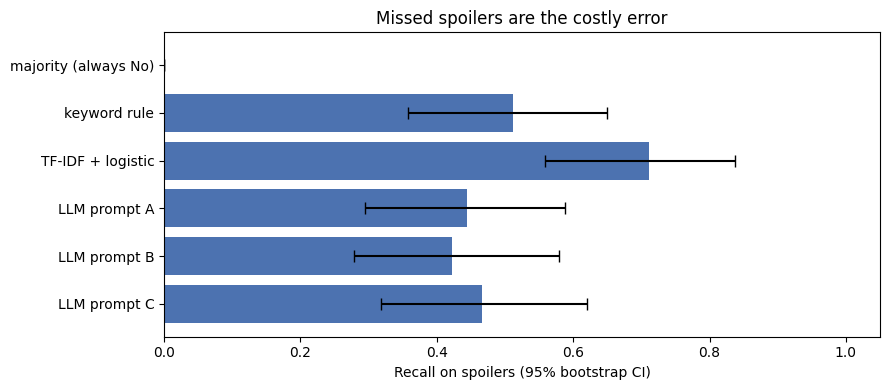

In [28]:
print("=" * 60)
print("PART 8a: CONFIDENCE INTERVALS")
print("=" * 60)
print()

boot_idx = rng.integers(0, len(val), size=(N_BOOT, len(val)))
boot_recall = {m: np.array([evaluate(true_labels[b], preds[m].values[b])["recall"] for b in boot_idx])
               for m in preds.columns}

ci_rows = []
for m in preds.columns:
    lo, hi = np.percentile(boot_recall[m], [2.5, 97.5])
    ci_rows.append({"method": m, "recall": round(results.loc[m, "recall"], 3), "95% CI": f"[{lo:.2f}, {hi:.2f}]"})
ci_table = pd.DataFrame(ci_rows)
print(ci_table.to_string(index=False))

print(f"\n### Is {best} meaningfully better? (paired difference in recall, same resamples) ###")
for m in preds.columns:
    if m == best:
        continue
    d = boot_recall[best] - boot_recall[m]
    lo, hi = np.percentile(d, [2.5, 97.5])
    verdict = "YES - CI excludes 0" if (lo > 0 or hi < 0) else "NO - CI includes 0"
    print(f"  vs {m:22s} diff = {results.loc[best, 'recall'] - results.loc[m, 'recall']:+.3f}  [{lo:+.2f}, {hi:+.2f}]  {verdict}")

fig, ax = plt.subplots(figsize=(9, 4))
rec = results["recall"].astype(float)
err = [rec - [np.percentile(boot_recall[m], 2.5) for m in preds.columns],
       [np.percentile(boot_recall[m], 97.5) for m in preds.columns] - rec]
ax.barh(preds.columns, rec, xerr=err, color="#4C72B0", capsize=4)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Recall on spoilers (95% bootstrap CI)")
ax.set_title("Missed spoilers are the costly error")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/fig_recall.png", dpi=150)
plt.show()

In [29]:
print("=" * 60)
print("PART 8b: SUBGROUPS")
print("=" * 60)
print()

truth_by_id = pd.Series(true_labels, index=val["review_id"])
sub_rows = []
for name, ids in [("borderline", val.loc[val["borderline"], "review_id"]),
                  ("regular", val.loc[~val["borderline"], "review_id"])] + \
                 [(f"genre: {g}", grp["review_id"]) for g, grp in genres.groupby("genre_one")]:
    t = truth_by_id[ids].to_numpy()
    if (t == "Yes").sum() >= 5:                          # too few spoilers = no stable recall
        sub_rows.append({"group": name, "n_spoilers": int((t == "Yes").sum()),
                         "recall": round(evaluate(t, preds.loc[ids, best].values)["recall"], 3)})
subgroups = pd.DataFrame(sub_rows)
print(f"### Recall by subgroup ({best}) ###")
print(subgroups.to_string(index=False))

genre_recall = subgroups[subgroups["group"].str.startswith("genre")]["recall"]
recall_ratio = genre_recall.min() / genre_recall.max() if len(genre_recall) > 1 and genre_recall.max() > 0 else np.nan
print(f"\nGenre recall ratio (min/max): {recall_ratio:.2f}")
print("Work to do: below 0.80, one genre's spoilers are missed much more often" if recall_ratio < 0.8
      else "All good: no genre falls below four-fifths of the best genre's recall")

# Does the model say Unsure more on the reviews WE disagreed on?
disputed = (labels["braxton"] != labels["teenna"]).to_numpy()
print(f"\n### Unsure rate: reviews we disagreed on ({disputed.sum()}) vs. agreed on ({(~disputed).sum()}) ###")
for m in llm_cols:
    unsure = (preds[m] == "Unsure").to_numpy()
    print(f"  {m}: disputed {unsure[disputed].mean() if disputed.any() else float('nan'):.0%}   "
          f"agreed {unsure[~disputed].mean():.0%}")
if disputed.sum() < 10:
    print(f"Only {disputed.sum()} disputed reviews: a pattern to watch, not a finding.")

PART 8b: SUBGROUPS

### Recall by subgroup (LLM prompt C) ###
           group  n_spoilers  recall
      borderline          31   0.581
         regular          14   0.214
   genre: Action          21   0.524
genre: Adventure          15   0.267
   genre: Comedy          11   0.273
    genre: Crime           8   0.625
    genre: Drama          20   0.550
   genre: Family           5   0.200
  genre: Fantasy           6   0.167
  genre: Romance           6   0.500
   genre: Sci-Fi          12   0.583
 genre: Thriller           7   0.571

Genre recall ratio (min/max): 0.27
Work to do: below 0.80, one genre's spoilers are missed much more often

### Unsure rate: reviews we disagreed on (38) vs. agreed on (62) ###
  LLM prompt A: disputed 0%   agreed 0%
  LLM prompt B: disputed 0%   agreed 0%
  LLM prompt C: disputed 0%   agreed 0%


In [30]:
print("=" * 60)
print("PART 8c: HEADLINE NUMBERS")
print("=" * 60)
print()

headline = {
    "hand-label κ (before settling)": round(kappa, 3),
    "dataset tag agrees with our key": round(tag_agree, 3),
    "best prompt": best,
    "best prompt recall on spoilers": round(results.loc[best, "recall"], 3),
    "best prompt recall 95% CI": ci_table.set_index("method").loc[best, "95% CI"],
    "TF-IDF baseline recall": round(results.loc["TF-IDF + logistic", "recall"], 3),
    "share sent to a human (Unsure)": round(results.loc[best, "to_human"], 3),
    "genre recall ratio (min/max)": round(recall_ratio, 3),
    "API cost per 1,000 reviews (USD)": round(cost_per_text * 1000, 2),
    "rubric human-human κ (linear)": round(mean_kappa, 3),
    "rubric human-human exact agreement": round(exact_agree, 3),
    "rubric MDD (0-16)": round(mdd, 2),
}
for name, value in headline.items():
    print(f"  {name:40s} {value}")
pd.Series(headline, name="value").to_csv("outputs/headline_metrics.csv")
results.to_csv("outputs/results_table.csv")

PART 8c: HEADLINE NUMBERS

  hand-label κ (before settling)           0.299
  dataset tag agrees with our key          0.57
  best prompt                              LLM prompt C
  best prompt recall on spoilers           0.467
  best prompt recall 95% CI                [0.32, 0.62]
  TF-IDF baseline recall                   0.711
  share sent to a human (Unsure)           0.0
  genre recall ratio (min/max)             0.267
  API cost per 1,000 reviews (USD)         2.07
  rubric human-human κ (linear)            -0.015
  rubric human-human exact agreement       0.63
  rubric MDD (0-16)                        3.5


## Decision

No, a platform should not replace the checkbox with Claude alone. Prompt C caught only 0.47 of spoilers (95% CI 0.32 to 0.62), and our rule is to deploy only if recall’s lower CI bound is at least 0.80 on a new hand-labeled set. It answered Unsure 0% of the time, so nothing ever went to a human. The genre recall ratio was 0.27, well under 0.80, though the genre groups are small. It’s cheap at about $2.07 per 1,000 reviews, but missing spoilers is the costly mistake. Instead, we’d use the TF-IDF model (recall 0.71) to catch spoilers and show Claude’s one-line reason to a moderator, since its flags were 88% precise.

In [31]:
print()
print("=" * 60)
print("Checklist:")
print("  [x] Class 2: first call repeated and fact-checked")
print("  [x] Class 3-4: token counts, context window math, cost estimate before running")
print("  [x] Class 5: data quality issues found by code vs. the AI check (AI found / code found / AI missed)")
print("  [x] Class 5: data dictionary verified (not just AI-generated)")
print("  [x] Class 6: row counts after every cleaning step, two visualizations, key findings cross-checked")
print("  [x] Class 8: run_validation() passes; ask-three-times on parse_call() tested against real answers")
print("  [x] Class 11-12: 100 reviews hand-coded by both partners, κ computed before settling")
print("  [x] Class 11-12: sklearn baseline with CV F1, LLM classifier, precision/recall/F1, confusion matrix")
print("  [x] Class 11-12: cost per text projected to 10K/100K")
print("  [x] Class 7: impact of trusting the dataset tag quantified")
print("  [x] Class 13-14: rubric calibrated, 25 answers scored independently, human-human and human-LLM κ, 3 judge runs, MDD")
print("  [x] Every comparison has a CI or MDD; subgroup recall and four-fifths ratio")
print("  [x] AI use log complete (each partner)")
print("=" * 60)


Checklist:
  [x] Class 2: first call repeated and fact-checked
  [x] Class 3-4: token counts, context window math, cost estimate before running
  [x] Class 5: data quality issues found by code vs. the AI check (AI found / code found / AI missed)
  [x] Class 5: data dictionary verified (not just AI-generated)
  [x] Class 6: row counts after every cleaning step, two visualizations, key findings cross-checked
  [x] Class 8: run_validation() passes; ask-three-times on parse_call() tested against real answers
  [x] Class 11-12: 100 reviews hand-coded by both partners, κ computed before settling
  [x] Class 11-12: sklearn baseline with CV F1, LLM classifier, precision/recall/F1, confusion matrix
  [x] Class 11-12: cost per text projected to 10K/100K
  [x] Class 7: impact of trusting the dataset tag quantified
  [x] Class 13-14: rubric calibrated, 25 answers scored independently, human-human and human-LLM κ, 3 judge runs, MDD
  [x] Every comparison has a CI or MDD; subgroup recall and four-f